# ***Imports and setup***

In [ ]:
import os, pathlib, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# ***Download and inspect the dataset***

In [ ]:
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
tf.keras.utils.get_file("flower_photos.tgz", origin=url, extract=True)

# Finding the folder that directly contains the class folders (daisy, roses, ...)
datasets_root = pathlib.Path.home() / ".keras" / "datasets"
data_dir = next(p.parent for p in datasets_root.rglob("daisy") if p.is_dir())
print("Dataset folder:", data_dir)

Dataset folder: /root/.keras/datasets/flower_photos_extracted/flower_photos


{'daisy': 633, 'dandelion': 898, 'roses': 641, 'sunflowers': 699, 'tulips': 799}
Total images: 3670


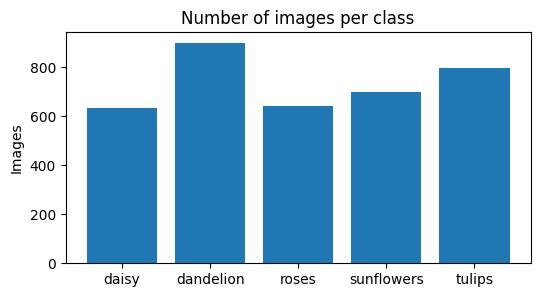

In [ ]:
# Count images per class (each sub-folder = one class)
class_counts = {
    folder.name: len(list(folder.glob("*.jpg")))
    for folder in sorted(data_dir.iterdir()) if folder.is_dir()
}
print(class_counts)
print("Total images:", sum(class_counts.values()))

# Bar chart of class balance (useful for your report)
plt.figure(figsize=(6, 3))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Number of images per class")
plt.ylabel("Images")
plt.show()

# ***Visualise Sample Images***

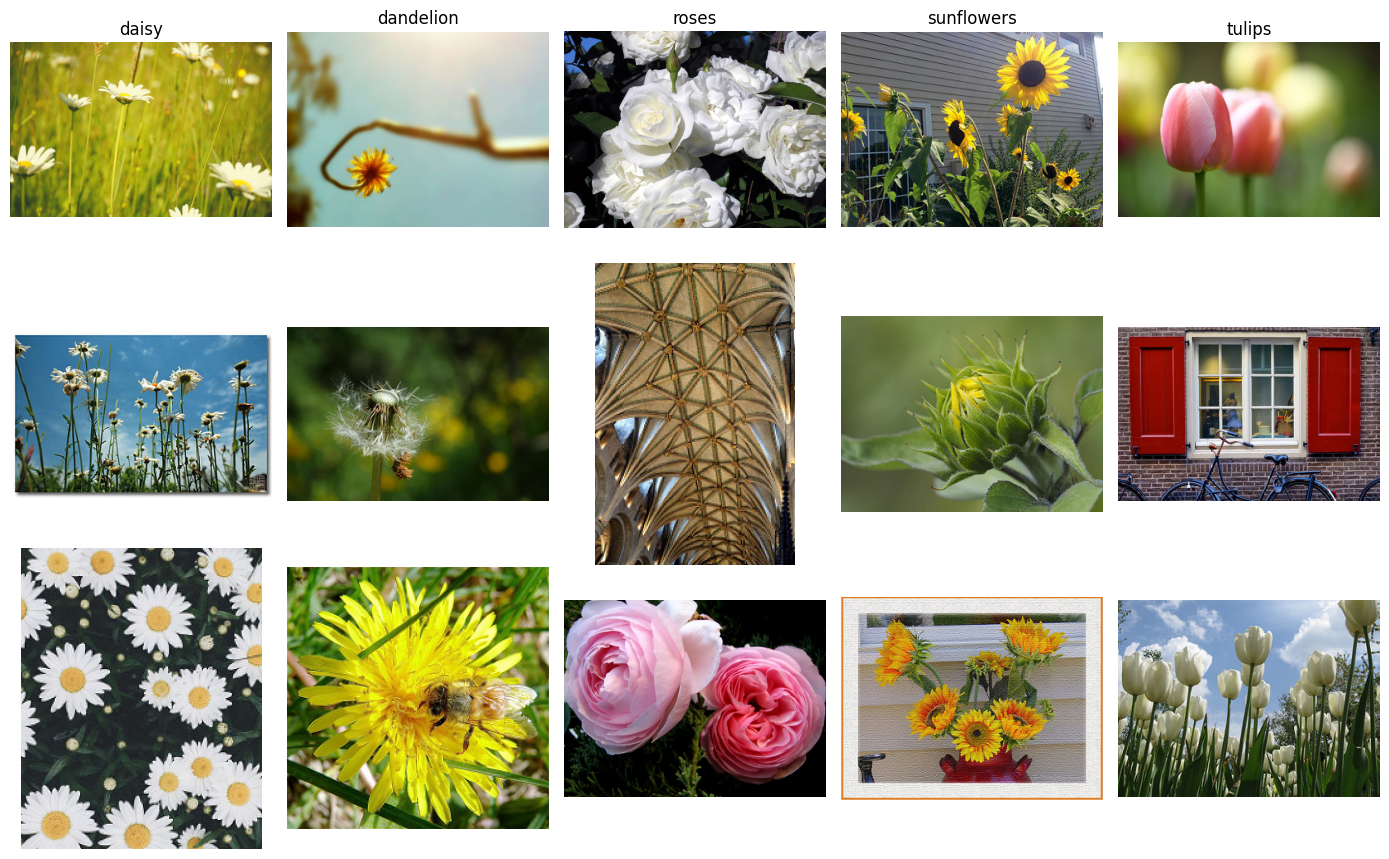

In [ ]:
class_names = sorted(class_counts.keys())

fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for col, cls in enumerate(class_names):
    files = list((data_dir / cls).glob("*.jpg"))
    for row, path in enumerate(random.sample(files, 3)):   # 3 random images per class
        axes[row, col].imshow(plt.imread(path))
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(cls, fontsize=12)
plt.tight_layout()
plt.show()

# ***Load the datasets and optimise the pipeline***
> ##  Load Train/Validation Data






In [ ]:
IMG_SIZE   = (128, 128)
BATCH_SIZE = 32
VAL_SPLIT  = 0.2

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=VAL_SPLIT, subset="training",
    seed=123, image_size=IMG_SIZE, batch_size=BATCH_SIZE)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=VAL_SPLIT, subset="validation",
    seed=123, image_size=IMG_SIZE, batch_size=BATCH_SIZE)

class_names = train_ds.class_names      # label index -> name (alphabetical order)
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

# Speed up the input pipeline
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


# ***Baseline CNN (no augmentation, no Dropout)***

In [ ]:
def build_cnn(improved=False):
    """Builds the CNN. improved=True adds data augmentation + Dropout."""
    model = models.Sequential()
    model.add(layers.Input(shape=(128, 128, 3)))

    # Data augmentation (only the improved model). Active only during training.
    if improved:
        model.add(layers.RandomFlip("horizontal"))
        model.add(layers.RandomRotation(0.1))
        model.add(layers.RandomZoom(0.1))

    # Scale pixel values from 0-255 to 0-1
    model.add(layers.Rescaling(1.0 / 255))

    # Three convolution blocks: find patterns, then shrink the image
    model.add(layers.Conv2D(32, 3, padding="same", activation="relu"))
    model.add(layers.MaxPooling2D())
    model.add(layers.Conv2D(64, 3, padding="same", activation="relu"))
    model.add(layers.MaxPooling2D())
    model.add(layers.Conv2D(128, 3, padding="same", activation="relu"))
    model.add(layers.MaxPooling2D())
    if improved:
        model.add(layers.Dropout(0.25))

    # Classifier head
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    if improved:
        model.add(layers.Dropout(0.5))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))  # 5 probabilities
    return model


baseline_model = build_cnn(improved=False)
baseline_model.summary()

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # labels are integers 0-4
    metrics=["accuracy"])

EPOCHS_BASELINE = 15
history_base = baseline_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,325 (16.36 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 116ms/step - accuracy: 0.3777 - loss: 1.4345 - val_accuracy: 0.5559 - val_loss: 1.1404
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5855 - loss: 1.0560 - val_accuracy: 0.6035 - val_loss: 1.0179
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6693 - loss: 0.8705 - val_accuracy: 0.5790 - val_loss: 1.0168
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.7292 - loss: 0.7131 - val_accuracy: 0.6444 - val_loss: 0.9212
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.8055 - loss: 0.5280 - val_accuracy: 0.6608 - val_loss: 1.0012
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8757 - loss: 0.3539 - val_accuracy: 0.6335 - val_loss: 1.0143
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9108 - loss: 0.2660 - val_accuracy: 0.6417 - val_loss: 1.1612
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9462 - loss: 0.1708 - val_accuracy: 0.6512 -

# ***Baseline Model Training Curves***

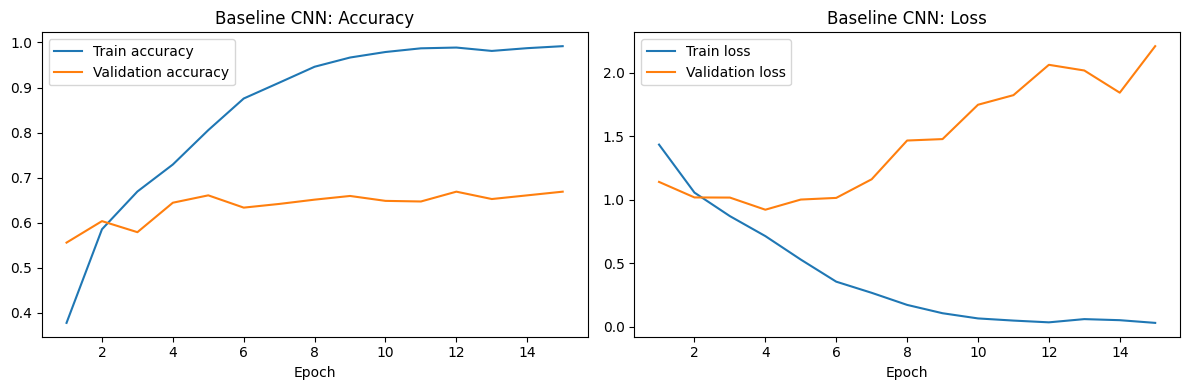

In [ ]:
def plot_history(history, title):
    """Plots accuracy and loss (train vs validation) for one model."""
    acc, val_acc = history.history["accuracy"], history.history["val_accuracy"]
    loss, val_loss = history.history["loss"], history.history["val_loss"]
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label="Train accuracy")
    plt.plot(epochs, val_acc, label="Validation accuracy")
    plt.title(f"{title}: Accuracy"); plt.xlabel("Epoch"); plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label="Train loss")
    plt.plot(epochs, val_loss, label="Validation loss")
    plt.title(f"{title}: Loss"); plt.xlabel("Epoch"); plt.legend()
    plt.tight_layout()
    plt.show()

plot_history(history_base, "Baseline CNN")

# ***Improved CNN (augmentation + Dropout)***

In [ ]:
improved_model = build_cnn(improved=True)
improved_model.summary()

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

EPOCHS_IMPROVED = 25
history_imp = improved_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_IMPROVED)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,325 (16.36 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - accuracy: 0.3988 - loss: 1.3733 - val_accuracy: 0.4864 - val_loss: 1.2127
Epoch 2/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.5490 - loss: 1.1264 - val_accuracy: 0.6022 - val_loss: 1.0588
Epoch 3/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.5926 - loss: 1.0382 - val_accuracy: 0.6063 - val_loss: 1.0067
Epoch 4/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6352 - loss: 0.9539 - val_accuracy: 0.6267 - val_loss: 0.9441
Epoch 5/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.6608 - loss: 0.9056 - val_accuracy: 0.6812 - val_loss: 0.7773
Epoch 6/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.6717 - loss: 0.8601 - val_accuracy: 0.6771 - val_loss: 0.8515
Epoch 7/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.6805 - loss: 0.8236 - val_accuracy: 0.6839 - val_loss: 0.7909
Epoch 8/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.6924 - loss: 0.8265 - val_accuracy: 0.6907 - v

# ***Improved Curves and Before/After Comparison***

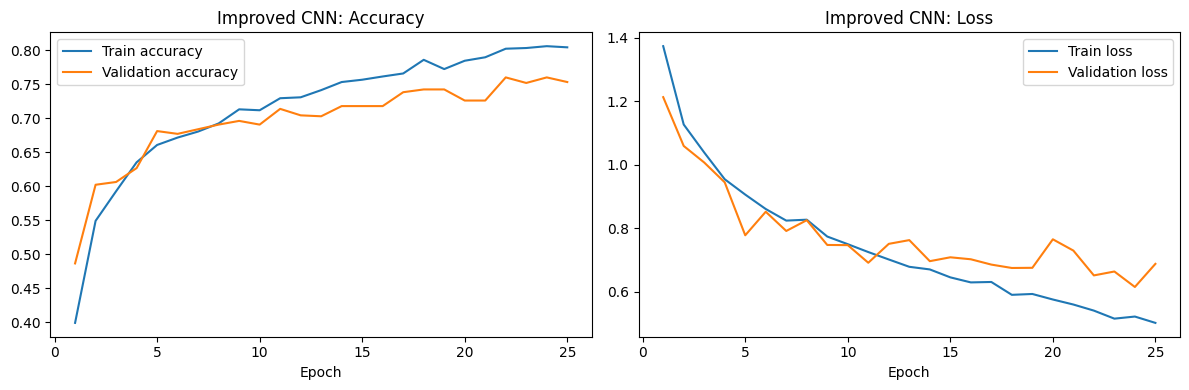

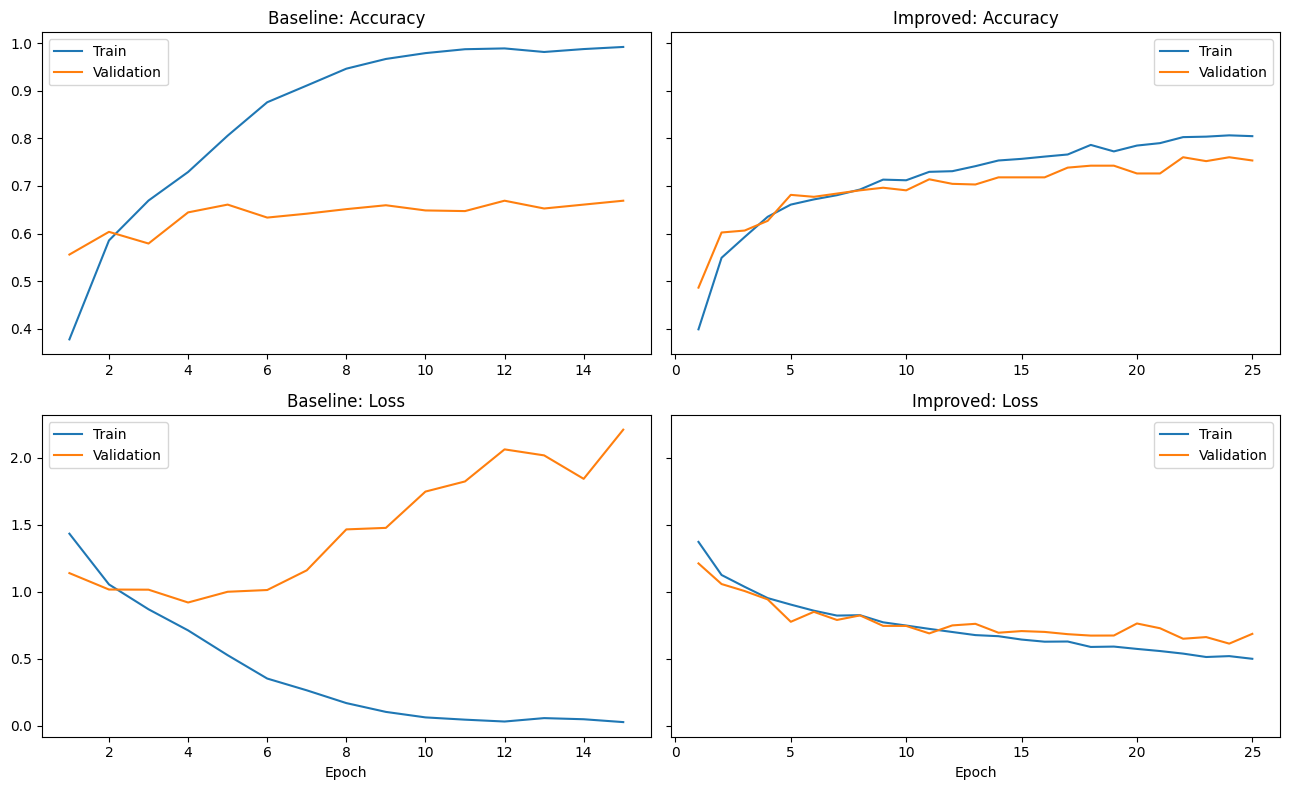

In [ ]:
plot_history(history_imp, "Improved CNN")

# Side-by-side: columns = model, rows = metric
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey="row")
for col, (hist, name) in enumerate([(history_base, "Baseline"),
                                    (history_imp, "Improved")]):
    h = hist.history
    ep = range(1, len(h["accuracy"]) + 1)
    axes[0, col].plot(ep, h["accuracy"], label="Train")
    axes[0, col].plot(ep, h["val_accuracy"], label="Validation")
    axes[0, col].set_title(f"{name}: Accuracy")
    axes[1, col].plot(ep, h["loss"], label="Train")
    axes[1, col].plot(ep, h["val_loss"], label="Validation")
    axes[1, col].set_title(f"{name}: Loss")
    axes[1, col].set_xlabel("Epoch")
    axes[0, col].legend(); axes[1, col].legend()
plt.tight_layout()
plt.show()

# ***Evaluation on the Validation Set***

Best model: Improved


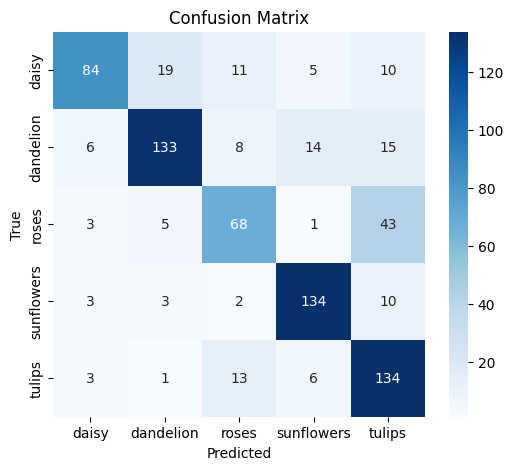

              precision    recall  f1-score   support

       daisy       0.85      0.65      0.74       129
   dandelion       0.83      0.76      0.79       176
       roses       0.67      0.57      0.61       120
  sunflowers       0.84      0.88      0.86       152
      tulips       0.63      0.85      0.73       157

    accuracy                           0.75       734
   macro avg       0.76      0.74      0.74       734
weighted avg       0.76      0.75      0.75       734



In [ ]:
# Choose the better model by final validation accuracy
_, base_val_acc = baseline_model.evaluate(val_ds, verbose=0)
_, imp_val_acc  = improved_model.evaluate(val_ds, verbose=0)
best_model = improved_model if imp_val_acc >= base_val_acc else baseline_model
print("Best model:", "Improved" if best_model is improved_model else "Baseline")

# Collect true labels, predictions and images in ONE pass
# (same loop = same order, so labels and predictions always match)
y_true, y_pred, val_images = [], [], []
for images, labels in val_ds:
    probs = best_model.predict(images, verbose=0)       # shape (batch, 5)
    y_pred.extend(np.argmax(probs, axis=1))             # highest probability wins
    y_true.extend(labels.numpy())
    val_images.extend(images.numpy().astype("uint8"))
y_true, y_pred = np.array(y_true), np.array(y_pred)

# Confusion matrix heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.show()

# Precision / recall / F1 per class
print(classification_report(y_true, y_pred, target_names=class_names))

# ***Misclassified Images and Error Analysis***

Misclassified: 181 of 734


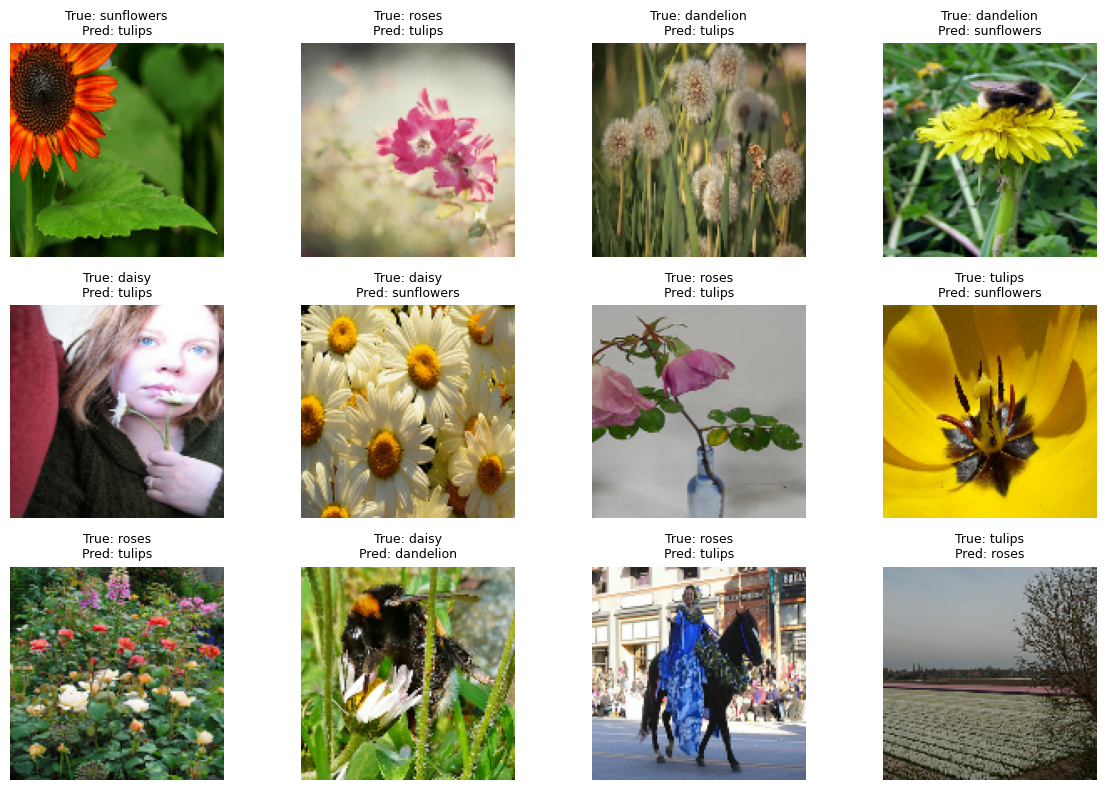

In [ ]:
wrong = np.where(y_true != y_pred)[0]
print(f"Misclassified: {len(wrong)} of {len(y_true)}")

plt.figure(figsize=(12, 8))
for i, idx in enumerate(wrong[:12]):                    # first 12 mistakes
    plt.subplot(3, 4, i + 1)
    plt.imshow(val_images[idx])
    plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}",
              fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

# ***Prediction on a New Flower Image***

117948/117948 ━━━━━━━━━━━━━━━━━━━━ 0s 4us/step


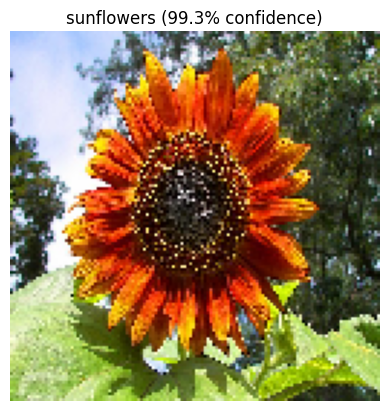

daisy          0.0%
dandelion      0.0%
roses          0.0%
sunflowers    99.3%
tulips         0.7%


In [ ]:
def predict_image(img_path, model):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)   # load + resize
    arr = tf.keras.utils.img_to_array(img)                          # to numpy
    arr = np.expand_dims(arr, axis=0)                               # add batch dimension
    probs = model.predict(arr, verbose=0)[0]                        # 5 probabilities
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[np.argmax(probs)]} ({100 * np.max(probs):.1f}% confidence)")
    plt.show()
    for name, p in zip(class_names, probs):
        print(f"{name:12s} {100 * p:5.1f}%")

# Option A: from a URL (this sunflower image is used in the official TF tutorial;
# if the link is ever dead, use Option B or any direct .jpg link)
sunflower_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/592px-Red_sunflower.jpg"
sunflower_path = tf.keras.utils.get_file("Red_sunflower", origin=sunflower_url)
predict_image(sunflower_path, best_model)


# ***Save and Load the Model***

In [ ]:
best_model.save("flower_cnn.keras")

loaded_model = tf.keras.models.load_model("flower_cnn.keras")
print("Loaded OK. Validation accuracy:", loaded_model.evaluate(val_ds, verbose=0)[1])

# download
from google.colab import files
files.download("flower_cnn.keras")

Loaded OK. Validation accuracy: 0.7534059882164001


# ***Final Results: Baseline vs Improved***

In [ ]:
def summarize(hist, name):
    h = hist.history
    return {
        "Model": name,
        "Epochs": len(h["accuracy"]),
        "Final train acc": round(h["accuracy"][-1], 4),
        "Final val acc": round(h["val_accuracy"][-1], 4),
        "Best val acc": round(max(h["val_accuracy"]), 4),
        "Final train loss": round(h["loss"][-1], 4),
        "Final val loss": round(h["val_loss"][-1], 4),
        "Acc gap (train - val)": round(h["accuracy"][-1] - h["val_accuracy"][-1], 4),
    }

results = pd.DataFrame([
    summarize(history_base, "Baseline CNN"),
    summarize(history_imp, "Improved CNN (aug + dropout)")])
results.T       # transposed so it fits on screen; screenshot this for your report

,0,1
Model,Baseline CNN,Improved CNN (aug + dropout)
Epochs,15,25
Final train acc,0.9918,0.8045
Final val acc,0.6689,0.7534
Best val acc,0.6689,0.7602
Final train loss,0.029,0.5012
Final val loss,2.2104,0.6872
Acc gap (train - val),0.3229,0.0511
